# Deploy or Deny: Cost-Sensitive Fraud Detection with Business-Aware Threshold Optimisation

---

## Business Context

Simulating working with the Risk & Trust team at a fast-growing fintech. The fraud team has been using a rules-based system — simple thresholds like "flag any transaction over £2,000 from a new device". It works badly. Too many good customers get blocked. Too much fraud slips through.

Goal: **build a machine learning fraud detection model and critically decide where to set the decision threshold before it goes live.**


---

## The Dataset: IEEE-CIS Fraud Detection

This dataset was released by Vesta Corporation (a real payment processor) in partnership with the IEEE Computational Intelligence Society. It contains real transaction data with anonymised features which is exactly what you'd work with inside a fintech.

Two tables:
- **train_transaction.csv** — the core transaction data (~590k rows)
- **train_identity.csv** — device/identity signals joined on `TransactionID`

Features include transaction amounts, time deltas, card details, email domains, device types, and 339 anonymised `V` columns (engineered by Vesta's internal team — you don't know what they mean, and that's intentional).

The target column is `isFraud` — binary, 1 = fraud, 0 = legitimate.

---

## What We're Building (and Why Each Step Matters)

| Phase | What | Why It Impresses |
|---|---|---|
| EDA | Understand data quality, imbalance, time structure | Shows analytical rigour, not just model-fitting |
| Feature Engineering | Create signals from raw fields | Where real DS value gets added |
| Baseline Model | Logistic Regression with time-based split | Proves you understand *why* random splits are wrong in production |
| Champion Model | LightGBM with class imbalance handling | What fintechs actually use |
| Threshold Optimisation | Cost matrix → optimal deployment point | The differentiating piece almost no candidate does |
| SHAP Explainability | Feature importance with directional insight | Regulatory awareness (explainability requirements) |
| Deployment Simulation | 30-day business impact projection | Turns a model into a business recommendation |


---

## Phase 0: Environment Setup

Before anything else, we import our libraries and configure notebook-wide settings.

**Why these libraries?**
- `pandas` / `numpy` — the backbone of any data work
- `matplotlib` / `seaborn` — visualisation; seaborn gives us nicer defaults faster
- `sklearn` — preprocessing, metrics, baseline models
- `lightgbm` — gradient boosted trees, fast on Apple Silicon, what most fintechs use in production
- `shap` — model explainability; required for any regulated use case
- `imblearn` — tools for handling class imbalance (SMOTE etc.)


In [1]:
# ── Core data manipulation ──────────────────────────────────────────────────
import pandas as pd
import numpy as np

# ── Visualisation ───────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ── Scikit-learn: preprocessing, models, metrics ────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    RocCurveDisplay
)
from sklearn.pipeline import Pipeline

# ── LightGBM: our champion model ────────────────────────────────────────────
import lightgbm as lgb

# ── SHAP: model explainability ───────────────────────────────────────────────
import shap

# ── Class imbalance handling ─────────────────────────────────────────────────
from imblearn.over_sampling import SMOTE

# ── Standard library ─────────────────────────────────────────────────────────
import warnings
import os

# ── Global settings ──────────────────────────────────────────────────────────
warnings.filterwarnings('ignore')          # suppress noisy convergence warnings
pd.set_option('display.max_columns', 50)  # show more columns in outputs
pd.set_option('display.float_format', '{:.4f}'.format)  # clean float display

# Seaborn theme — clean, professional, works well in dark and light notebooks
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)

# Reproducibility: fix random seeds everywhere we use randomness
SEED = 42
np.random.seed(SEED)

print("✅ Environment ready.")
print(f"   LightGBM version : {lgb.__version__}")
print(f"   pandas version   : {pd.__version__}")

/Users/sherifdeenoloye/Library/Python/3.9/lib/python/site-packages/dask/dataframe/__init__.py:42: FutureWarning: 
Dask dataframe query planning is disabled because dask-expr is not installed.

You can install it with `pip install dask[dataframe]` or `conda install dask`.
This will raise in a future version.

  warnings.warn(msg, FutureWarning)


✅ Environment ready.
   LightGBM version : 4.6.0
   pandas version   : 2.3.3


---

## Phase 1: Data Loading

The IEEE-CIS dataset comes in two tables that need to be joined:

1. **train_transaction.csv** — every transaction, with amount, card info, time, and 339 `V` features
2. **train_identity.csv** — device/browser/email signals for a *subset* of transactions (not every transaction has identity data — about 144k of 590k do)

We join them on `TransactionID` using a **left join** — keeping all transactions and filling identity gaps with NaN.

> In production, identity signals often arrive asynchronously — a transaction fires, and the device fingerprint comes in milliseconds later. A left join mirrors this: you score the transaction with whatever you have, and identity features gracefully degrade to NaN when absent. Dropping those rows (inner join) would silently bias your training data.


In [2]:
# ── File paths — adjust if your data lives elsewhere ─────────────────────────
DATA_DIR = os.path.expanduser('~/Desktop/fraud_detection/data/')

TRANSACTION_PATH = os.path.join(DATA_DIR, 'train_transaction.csv')
IDENTITY_PATH    = os.path.join(DATA_DIR, 'train_identity.csv')

# ── Load transaction table ────────────────────────────────────────────────────
# dtype specification on the V columns would speed this up; for now we let
# pandas infer — acceptable for an exploratory notebook
print("Loading transaction data (this may take ~30 seconds on first run)...")
df_trans = pd.read_csv(TRANSACTION_PATH)
print(f"   Transactions loaded : {df_trans.shape[0]:,} rows × {df_trans.shape[1]} columns")

# ── Load identity table ───────────────────────────────────────────────────────
print("Loading identity data...")
df_id = pd.read_csv(IDENTITY_PATH)
print(f"   Identity rows loaded : {df_id.shape[0]:,} rows × {df_id.shape[1]} columns")

# ── Join: left join keeps all transactions; NaN where no identity record ───────
df = df_trans.merge(df_id, on='TransactionID', how='left')
print(f"\n✅ Merged dataset : {df.shape[0]:,} rows × {df.shape[1]} columns")

# Sanity check — row count should exactly match transaction table
assert df.shape[0] == df_trans.shape[0], "Row count mismatch after merge — investigate!"

Loading transaction data (this may take ~30 seconds on first run)...
   Transactions loaded : 590,540 rows × 394 columns
Loading identity data...
   Identity rows loaded : 144,233 rows × 41 columns

✅ Merged dataset : 590,540 rows × 434 columns


---

## Phase 2: Exploratory Data Analysis

EDA is not optional decoration. It's how you catch problems before they silently destroy model performance.

We'll look at:
1. **Class imbalance** — how rare is fraud?
2. **Temporal structure** — do transactions have a time axis we need to respect?
3. **Missing data** — which features are usable and which are mostly empty?
4. **Transaction amount distribution** — does fraud cluster at certain values?



  CLASS DISTRIBUTION
  Legitimate (0) :  569,877  (96.50%)
  Fraud      (1) :   20,663  (3.50%)

  Imbalance ratio : ~27:1  (legit:fraud)


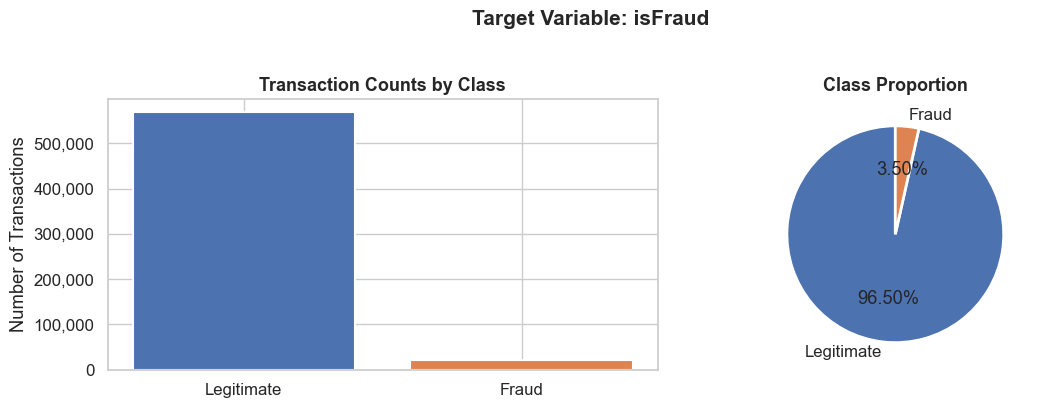

In [3]:
# ── 2.1  Target distribution — how imbalanced is this problem? ────────────────

fraud_counts = df['isFraud'].value_counts()
fraud_rate   = df['isFraud'].mean() * 100

print("=" * 45)
print("  CLASS DISTRIBUTION")
print("=" * 45)
print(f"  Legitimate (0) : {fraud_counts[0]:>8,}  ({100 - fraud_rate:.2f}%)")
print(f"  Fraud      (1) : {fraud_counts[1]:>8,}  ({fraud_rate:.2f}%)")
print("=" * 45)
print(f"\n  Imbalance ratio : ~{fraud_counts[0]//fraud_counts[1]}:1  (legit:fraud)")

# ── Why imbalance matters ─────────────────────────────────────────────────────
# A model that predicts EVERY transaction as legitimate would score ~96.5%
# accuracy. That's useless for fraud detection. This is why accuracy is a
# misleading metric here — we'll use Precision-Recall AUC instead.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Bar chart of raw counts
axes[0].bar(['Legitimate', 'Fraud'], fraud_counts.values,
             color=['#4C72B0', '#DD8452'], edgecolor='white', linewidth=1.5)
axes[0].set_title('Transaction Counts by Class', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Number of Transactions')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

# Pie chart — easier to show the proportion visually
axes[1].pie(fraud_counts.values,
             labels=['Legitimate', 'Fraud'],
             autopct='%1.2f%%',
             colors=['#4C72B0', '#DD8452'],
             startangle=90,
             wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Class Proportion', fontsize=13, fontweight='bold')

plt.suptitle('Target Variable: isFraud', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

TransactionDT range:
  Min : 86,400 seconds
  Max : 15,811,131 seconds
  Span: 182.0 days


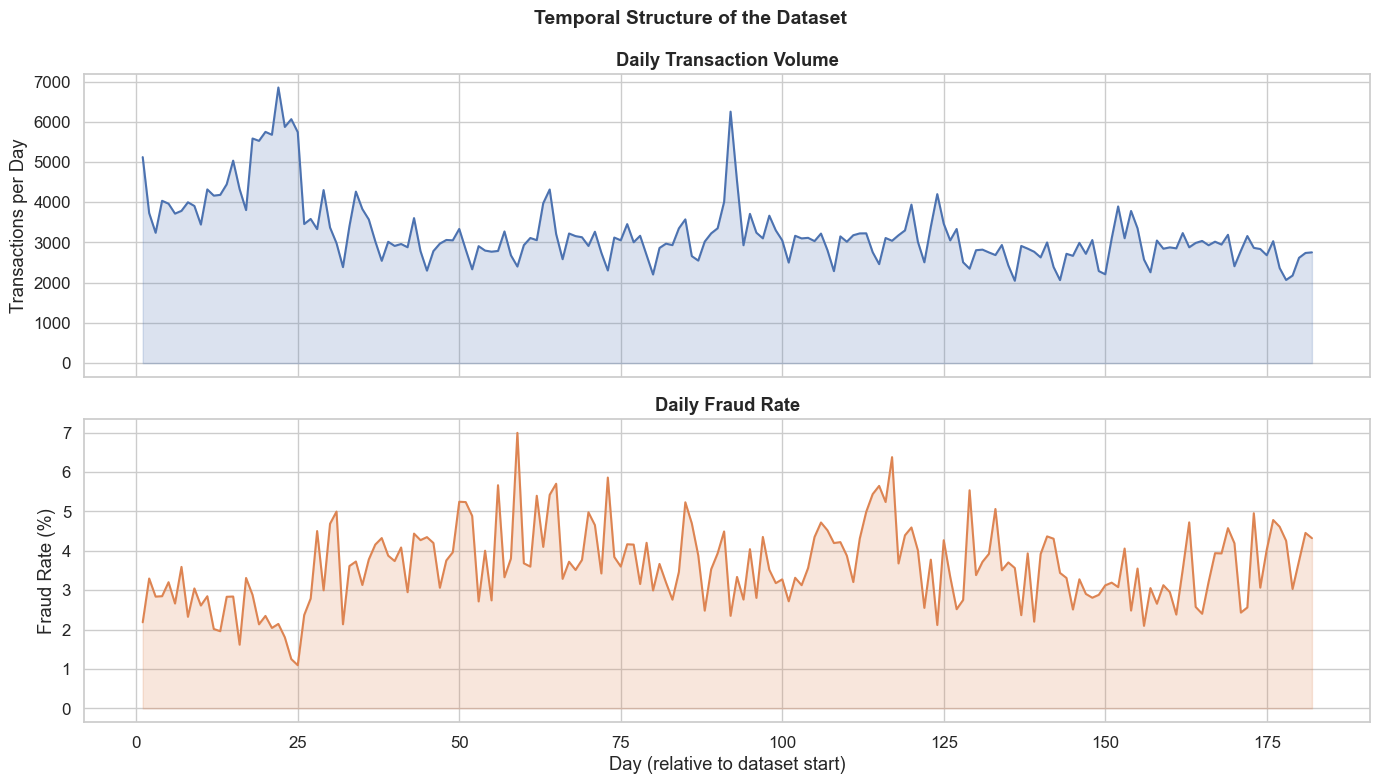


⚠️  Key insight: This dataset spans ~6 months.
   We MUST split train/test by time — not randomly.
   A random split would leak future information into training.
   In production, your model never sees the future.


In [4]:
# ── 2.2  Temporal structure — the most important EDA step for production ───────

# TransactionDT is seconds elapsed since some reference point (not a real
# timestamp, but it preserves the ordering of transactions in time)

print("TransactionDT range:")
print(f"  Min : {df['TransactionDT'].min():,} seconds")
print(f"  Max : {df['TransactionDT'].max():,} seconds")
print(f"  Span: {(df['TransactionDT'].max() - df['TransactionDT'].min()) / 86400:.1f} days")

# Convert to approximate day number for plotting
df['day'] = df['TransactionDT'] // 86400  # 86400 seconds = 1 day

# Count transactions and fraud per day
daily = df.groupby('day').agg(
    total_txns   = ('isFraud', 'count'),
    fraud_txns   = ('isFraud', 'sum')
).reset_index()
daily['fraud_rate'] = daily['fraud_txns'] / daily['total_txns']

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Top panel: daily transaction volume
axes[0].plot(daily['day'], daily['total_txns'], color='#4C72B0', linewidth=1.5)
axes[0].fill_between(daily['day'], daily['total_txns'], alpha=0.2, color='#4C72B0')
axes[0].set_ylabel('Transactions per Day')
axes[0].set_title('Daily Transaction Volume', fontweight='bold')

# Bottom panel: daily fraud rate — look for spikes or drift
axes[1].plot(daily['day'], daily['fraud_rate'] * 100, color='#DD8452', linewidth=1.5)
axes[1].fill_between(daily['day'], daily['fraud_rate'] * 100, alpha=0.2, color='#DD8452')
axes[1].set_ylabel('Fraud Rate (%)')
axes[1].set_xlabel('Day (relative to dataset start)')
axes[1].set_title('Daily Fraud Rate', fontweight='bold')

plt.suptitle('Temporal Structure of the Dataset', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\n⚠️  Key insight: This dataset spans ~6 months.")
print("   We MUST split train/test by time — not randomly.")
print("   A random split would leak future information into training.")
print("   In production, your model never sees the future.")

Columns with >70%  missing :  208  (we'll drop or flag these)
Columns with 20–70% missing:   44  (impute with median/mode)
Columns with <20%  missing :  162  (impute or keep as-is)
Complete columns           :   21


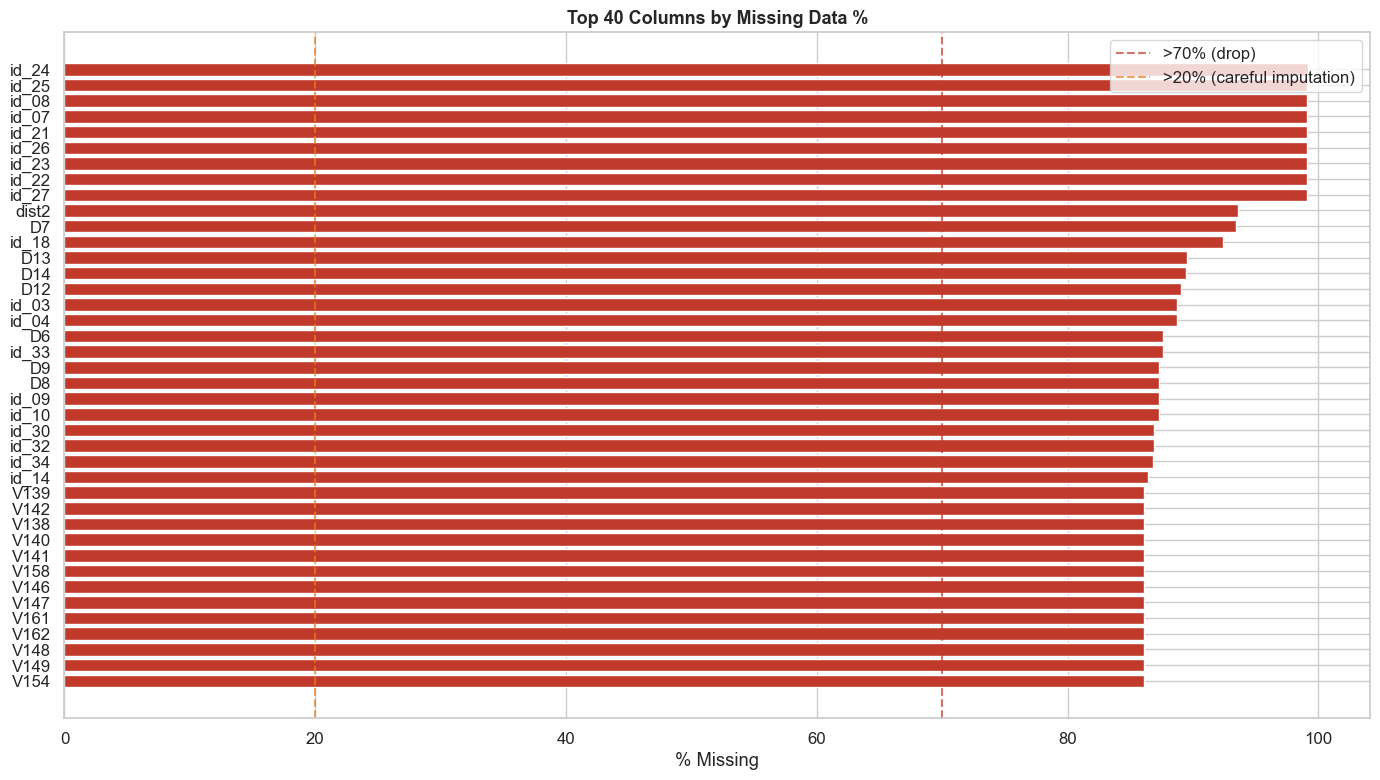

In [5]:
# ── 2.3  Missing data audit — which features are usable? ─────────────────────

# Calculate % missing per column
missing = (df.isnull().sum() / len(df) * 100).sort_values(ascending=False)

# Split into categories for readability
high_missing   = missing[missing > 70]   # essentially unusable without imputation
medium_missing = missing[(missing > 20) & (missing <= 70)]
low_missing    = missing[(missing > 0)   & (missing <= 20)]
complete       = missing[missing == 0]

print(f"Columns with >70%  missing : {len(high_missing):>4}  (we'll drop or flag these)")
print(f"Columns with 20–70% missing: {len(medium_missing):>4}  (impute with median/mode)")
print(f"Columns with <20%  missing : {len(low_missing):>4}  (impute or keep as-is)")
print(f"Complete columns           : {len(complete):>4}")

# Visualise the top 40 worst columns
fig, ax = plt.subplots(figsize=(14, 8))
top_missing = missing[missing > 0].head(40)

colors = ['#c0392b' if v > 70 else '#e67e22' if v > 20 else '#f1c40f'
          for v in top_missing.values]

ax.barh(top_missing.index[::-1], top_missing.values[::-1], color=colors[::-1])
ax.axvline(70, color='#c0392b', linestyle='--', alpha=0.7, label='>70% (drop)')
ax.axvline(20, color='#e67e22', linestyle='--', alpha=0.7, label='>20% (careful imputation)')
ax.set_xlabel('% Missing')
ax.set_title('Top 40 Columns by Missing Data %', fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

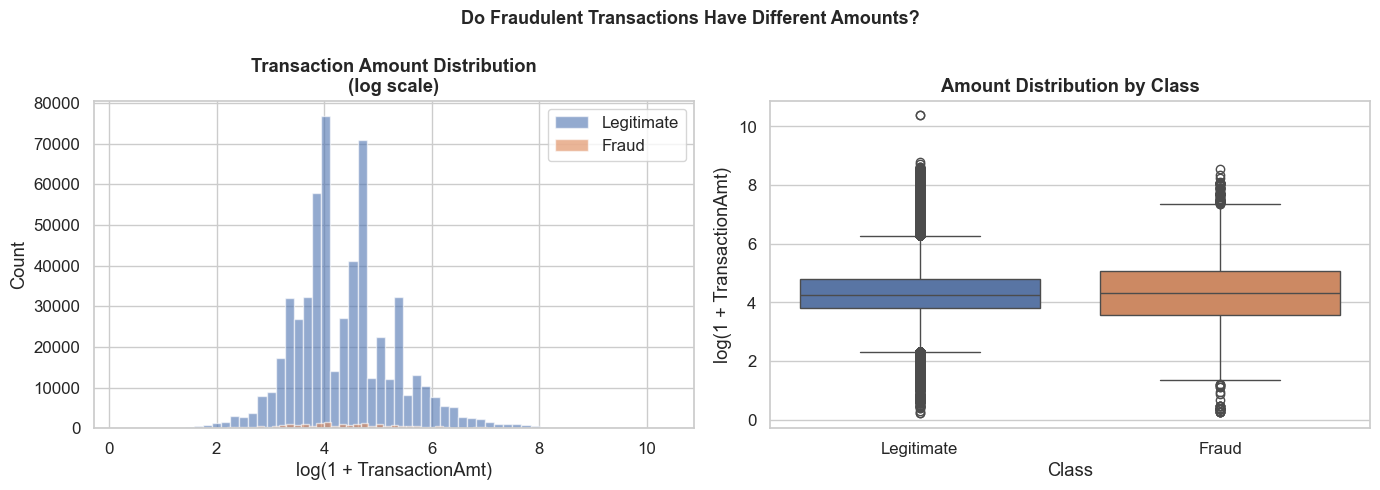


Median transaction amount:
isFraud
Legitimate   68.5000
Fraud        75.0000
Name: TransactionAmt, dtype: float64


In [6]:
# ── 2.4  Transaction amount — does fraud look different? ──────────────────────

# Log scale because transaction amounts are extremely right-skewed
# (a few huge transactions, many small ones)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: distribution by class on log scale
for fraud_label, color, label in [(0, '#4C72B0', 'Legitimate'), (1, '#DD8452', 'Fraud')]:
    subset = df[df['isFraud'] == fraud_label]['TransactionAmt']
    axes[0].hist(np.log1p(subset), bins=60, alpha=0.6, color=color, label=label)

axes[0].set_xlabel('log(1 + TransactionAmt)')
axes[0].set_ylabel('Count')
axes[0].set_title('Transaction Amount Distribution\n(log scale)', fontweight='bold')
axes[0].legend()

# Right: box plot for cleaner comparison of spread
plot_data = df[['TransactionAmt', 'isFraud']].copy()
plot_data['Class'] = plot_data['isFraud'].map({0: 'Legitimate', 1: 'Fraud'})
plot_data['log_amt'] = np.log1p(plot_data['TransactionAmt'])

sns.boxplot(data=plot_data, x='Class', y='log_amt', ax=axes[1],
            palette={'Legitimate': '#4C72B0', 'Fraud': '#DD8452'})
axes[1].set_ylabel('log(1 + TransactionAmt)')
axes[1].set_title('Amount Distribution by Class', fontweight='bold')

plt.suptitle('Do Fraudulent Transactions Have Different Amounts?', 
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Summary stats
print("\nMedian transaction amount:")
print(df.groupby('isFraud')['TransactionAmt'].median().rename({0: 'Legitimate', 1: 'Fraud'}))

---

## Phase 3: Feature Engineering

Raw features from the dataset are fine, but engineered features — signals derived from the raw data — are often what separates a good model from a great one.

We'll create:
1. **Log-transformed amount** — removes extreme skew; tree models handle it fine but logistic regression doesn't
2. **Time-of-day signals** — fraud patterns differ by hour (2am is different from 2pm)
3. **Missingness flags** — whether a feature is missing is itself informative ("why is device type absent for this transaction?")
4. **Categorical encoding** — convert string columns to numbers that models can use
5. **High-missingness column removal** — features that are >80% missing add noise, not signal




In [7]:
# ── 3.1  Core feature engineering ────────────────────────────────────────────

print("Engineering features...")

# Log-transform transaction amount
# Rationale: many ML algorithms (especially logistic regression) assume
# approximately normal input distributions. Log-transform compresses
# the long right tail of transaction amounts.
df['log_TransactionAmt'] = np.log1p(df['TransactionAmt'])  # log1p = log(1+x), safe for 0s

# Extract time-of-day from TransactionDT
# Fraud is not uniformly distributed across hours — late-night transactions
# and early-morning spikes are common fraud patterns
seconds_per_day  = 86400
seconds_per_hour = 3600
df['hour_of_day'] = (df['TransactionDT'] % seconds_per_day) // seconds_per_hour

# Day of week (0=Mon, 6=Sun) — weekend fraud patterns differ from weekday
df['day_of_week']  = (df['TransactionDT'] // seconds_per_day) % 7

# ── 3.2  Missingness flags for high-value identity columns ───────────────────
# The *absence* of identity information is a signal in itself.
# A card-present transaction with no device fingerprint is suspicious.

identity_cols = ['id_01', 'id_02', 'id_03', 'id_04', 'id_05',
                 'DeviceType', 'DeviceInfo']

for col in identity_cols:
    if col in df.columns:
        df[f'{col}_missing'] = df[col].isnull().astype(int)  # 1 if missing, 0 if present

print(f"   Added missingness flags for {len(identity_cols)} identity columns")

# ── 3.3  Drop columns with >80% missing — more noise than signal ─────────────
missing_pct = df.isnull().sum() / len(df)
cols_to_drop = missing_pct[missing_pct > 0.8].index.tolist()

# Never drop the target or the time column
cols_to_drop = [c for c in cols_to_drop if c not in ['isFraud', 'TransactionDT', 'day']]

df.drop(columns=cols_to_drop, inplace=True)
print(f"   Dropped {len(cols_to_drop)} columns with >80% missing values")

# ── 3.4  Encode categorical columns ──────────────────────────────────────────
# LightGBM can handle categoricals natively, but we need them as numeric codes.
# Logistic regression needs proper encoding (we'll handle that in the pipeline).

cat_cols = df.select_dtypes(include=['object']).columns.tolist()
print(f"   Encoding {len(cat_cols)} categorical columns")

for col in cat_cols:
    # Label encode: convert each unique string to an integer
    # NaN stays as NaN — LightGBM handles it natively
    df[col] = pd.Categorical(df[col]).codes  # -1 for NaN, 0+ for categories
    df[col] = df[col].replace(-1, np.nan)    # restore NaN for clarity

print("\n✅ Feature engineering complete.")
print(f"   Final dataset: {df.shape[0]:,} rows × {df.shape[1]} columns")

Engineering features...
   Added missingness flags for 7 identity columns
   Dropped 74 columns with >80% missing values
   Encoding 26 categorical columns

✅ Feature engineering complete.
   Final dataset: 590,540 rows × 371 columns


---

## Phase 4: Train / Test Split — The Right Way

This is arguably the most important modelling decision in the entire notebook.

**The wrong way (random split):** Shuffle rows, take 80% for training, 20% for test. This is what most tutorials do. It's wrong for time-series financial data because:
- It allows the model to see *future* transactions during training
- It inflates performance metrics (model "remembers" context from the future)
- It doesn't reflect how the model will actually be used in production

**The right way (time-based split):** Train on the first 5 months, test on the last month. This mirrors production: you train on historical data, deploy, and evaluate on transactions that arrive afterward.



In [8]:
# ── 4.1  Time-based train/test split ─────────────────────────────────────────

# Find the 80th percentile of TransactionDT — use first 80% of time as train,
# last 20% as test. Roughly 5 months train, 1 month test.
split_point = df['TransactionDT'].quantile(0.80)

train_df = df[df['TransactionDT'] <= split_point].copy()
test_df  = df[df['TransactionDT'] >  split_point].copy()

print("Train / Test Split Summary")
print("=" * 40)
print(f"  Train rows : {len(train_df):>8,}  ({len(train_df)/len(df)*100:.1f}%)")
print(f"  Test rows  : {len(test_df):>8,}  ({len(test_df)/len(df)*100:.1f}%)")
print(f"\n  Train fraud rate : {train_df['isFraud'].mean()*100:.2f}%")
print(f"  Test fraud rate  : {test_df['isFraud'].mean()*100:.2f}%")

# ── 4.2  Define feature columns ───────────────────────────────────────────────
# Exclude: TransactionID (identifier), TransactionDT (used only for splitting),
# day (derived from DT, would leak time), isFraud (target)

EXCLUDE_COLS = ['TransactionID', 'TransactionDT', 'day', 'isFraud']
FEATURE_COLS = [c for c in df.columns if c not in EXCLUDE_COLS]

print(f"\n  Feature columns used : {len(FEATURE_COLS)}")

# ── 4.3  Create X / y arrays ──────────────────────────────────────────────────
X_train = train_df[FEATURE_COLS]
y_train = train_df['isFraud']

X_test  = test_df[FEATURE_COLS]
y_test  = test_df['isFraud']

print(f"\n✅ Split complete.")
print(f"   X_train : {X_train.shape}  |  y_train fraud count : {y_train.sum():,}")
print(f"   X_test  : {X_test.shape}   |  y_test  fraud count : {y_test.sum():,}")

Train / Test Split Summary
  Train rows :  472,432  (80.0%)
  Test rows  :  118,108  (20.0%)

  Train fraud rate : 3.51%
  Test fraud rate  : 3.44%

  Feature columns used : 367

✅ Split complete.
   X_train : (472432, 367)  |  y_train fraud count : 16,599
   X_test  : (118108, 367)   |  y_test  fraud count : 4,064


---

## Phase 5: Baseline Model — Logistic Regression

Before reaching for the most powerful model, always establish a **baseline**. This serves three purposes:

1. **Sanity check** — if your fancy model doesn't beat logistic regression, something is wrong
2. **Benchmark** — you now have a reference point to measure improvement
3. **Interpretability** — logistic regression coefficients are directly readable; useful if you need a quick explainability story

We use a `Pipeline` here — a scikit-learn object that chains preprocessing and modelling together. This prevents **data leakage**: the scaler fits on training data only, then transforms test data using training statistics. Fitting the scaler on all data before splitting would leak test set information into preprocessing.



In [9]:
# ── 5.1  Prepare data for logistic regression ─────────────────────────────────
# Logistic regression is sensitive to missing values — impute with median
# (median is more robust to outliers than mean)

# Simple median imputation — in production you'd use a more sophisticated
# approach, but for a baseline this is standard
X_train_lr = X_train.fillna(X_train.median())
X_test_lr  = X_test.fillna(X_train.median())  # use TRAIN median for test — no leakage

# ── 5.2  Build and train the pipeline ────────────────────────────────────────
# Pipeline ensures scaler never sees test data during fit
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),     # normalise features to zero mean, unit variance
    ('model',  LogisticRegression(   # the actual classifier
        class_weight='balanced',     # automatically upweights the minority class (fraud)
        max_iter=500,                # increase from default 100 — dataset is large
        C=0.1,                       # regularisation strength; smaller = more regularised
        solver='saga',               # fast solver for large datasets
        random_state=SEED
    ))
])

print("Training Logistic Regression baseline...")
lr_pipeline.fit(X_train_lr, y_train)
print("✅ Training complete.")

# ── 5.3  Generate probability scores (not just 0/1 predictions) ───────────────
# We want probabilities, not hard labels — threshold optimisation requires them
lr_probs = lr_pipeline.predict_proba(X_test_lr)[:, 1]  # column 1 = P(fraud)

# ── 5.4  Evaluate — but using the RIGHT metrics ───────────────────────────────
# For imbalanced classification:
#   ROC-AUC   : overall ability to rank fraud above legit (good general metric)
#   PR-AUC    : precision-recall trade-off — better when positive class is rare
#   We report BOTH and explain why PR-AUC is more informative here

lr_roc_auc = roc_auc_score(y_test, lr_probs)
lr_pr_auc  = average_precision_score(y_test, lr_probs)

print("\nBaseline Logistic Regression Performance:")
print(f"  ROC-AUC : {lr_roc_auc:.4f}")
print(f"  PR-AUC  : {lr_pr_auc:.4f}")
print("\n  (PR-AUC is the more meaningful metric here — ROC-AUC can be")
print("   misleadingly optimistic on heavily imbalanced datasets)")

Training Logistic Regression baseline...
✅ Training complete.

Baseline Logistic Regression Performance:
  ROC-AUC : 0.8253
  PR-AUC  : 0.1761

  (PR-AUC is the more meaningful metric here — ROC-AUC can be
   misleadingly optimistic on heavily imbalanced datasets)


---

## Phase 6: Champion Model — LightGBM

LightGBM is a gradient boosted decision tree framework developed by Microsoft. It's the go-to model for tabular fraud detection in production fintech for several reasons:

- **Handles missing values natively** — no imputation needed; the tree learns which direction to send NaN values
- **Fast on large datasets** — histogram-based splitting, works well on Apple Silicon
- **Built-in class imbalance handling** — `scale_pos_weight` parameter
- **Works well on mixed feature types** — anonymised V columns, categoricals, numerics
- **Widely used in production** — Stripe, PayPal, and most major fintechs have LightGBM in their fraud stack

We'll use `scale_pos_weight` to compensate for the imbalance rather than SMOTE — SMOTE creates synthetic samples which can cause its own issues (synthetic frauds don't reflect real fraud patterns).


In [10]:
# ── 6.1  Calculate class weight for imbalance compensation ───────────────────
# scale_pos_weight = (number of negative samples) / (number of positive samples)
# This tells LightGBM: "each fraud example counts this many times more"

n_legit = (y_train == 0).sum()
n_fraud = (y_train == 1).sum()
scale_pos_weight = n_legit / n_fraud

print(f"Class weight ratio (legit/fraud) : {scale_pos_weight:.1f}")
print("This penalises missed frauds ~{:.0f}x more than missed legitimates".format(scale_pos_weight))

# ── 6.2  Define and train LightGBM ───────────────────────────────────────────
lgb_model = lgb.LGBMClassifier(
    # Core parameters
    n_estimators      = 500,           # number of boosting rounds (trees)
    learning_rate     = 0.05,          # lower = more trees needed but better generalisation
    max_depth         = 6,             # max depth of each tree — controls overfitting
    num_leaves        = 31,            # max leaves per tree; 2^max_depth is the theoretical max

    # Regularisation — prevents overfitting on noisy anonymised features
    reg_alpha         = 0.1,           # L1 regularisation (sparsity)
    reg_lambda        = 0.1,           # L2 regularisation (smoothness)
    min_child_samples = 20,            # min data in a leaf — prevents overfitting to tiny groups

    # Sampling — training each tree on a random subset of data/features (like random forests)
    subsample         = 0.8,           # use 80% of rows for each tree
    colsample_bytree  = 0.8,           # use 80% of features for each tree

    # Imbalance handling
    scale_pos_weight  = scale_pos_weight,  # upweight fraud class
    is_unbalance      = False,         # False when using scale_pos_weight

    # Hardware / reproducibility
    device            = 'cpu',         # M5 chip — LightGBM runs efficiently on CPU
    random_state      = SEED,
    verbose           = -1,            # suppress training output (very noisy otherwise)
    n_jobs            = -1,            # use all CPU cores
)

print("\nTraining LightGBM champion model...")
print("(This may take 2–5 minutes on ~470k training rows)")

lgb_model.fit(
    X_train, y_train,
    # LightGBM handles NaN natively — no need to impute
)

print("✅ LightGBM training complete.")

Class weight ratio (legit/fraud) : 27.5
This penalises missed frauds ~27x more than missed legitimates

Training LightGBM champion model...
(This may take 2–5 minutes on ~470k training rows)
✅ LightGBM training complete.


Model Comparison:
  Model                        ROC-AUC     PR-AUC
  ------------------------------------------------
  Logistic Regression           0.8253     0.1761
  LightGBM                      0.9049     0.5137

  LightGBM lift: +9.6% ROC-AUC, +191.7% PR-AUC


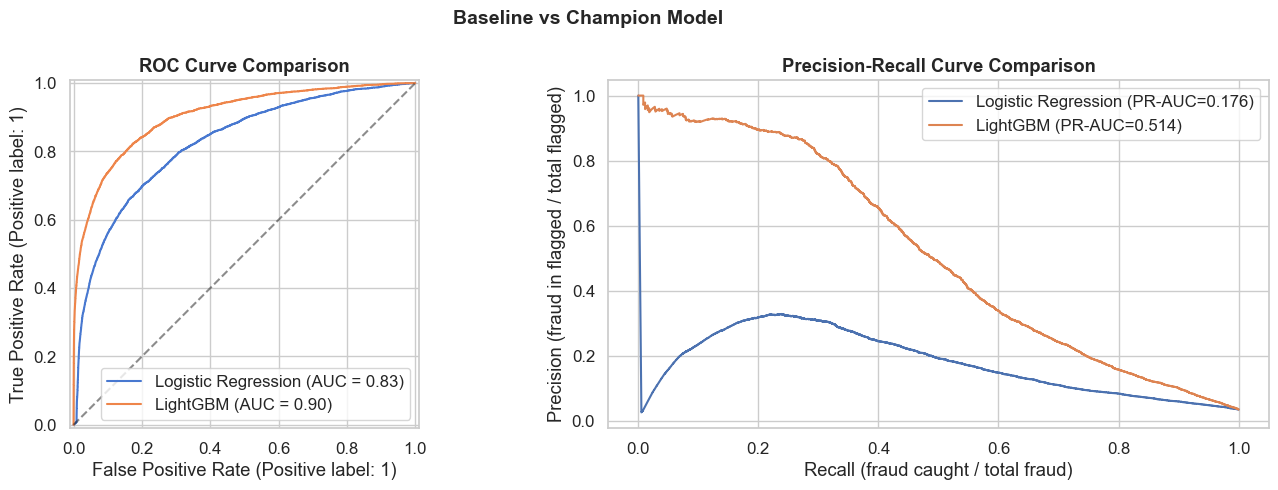

In [11]:
# ── 6.3  Evaluate LightGBM and compare to baseline ───────────────────────────

lgb_probs  = lgb_model.predict_proba(X_test)[:, 1]  # fraud probability scores

lgb_roc_auc = roc_auc_score(y_test, lgb_probs)
lgb_pr_auc  = average_precision_score(y_test, lgb_probs)

print("Model Comparison:")
print("=" * 50)
print(f"  {'Model':<25} {'ROC-AUC':>10} {'PR-AUC':>10}")
print("  " + "-" * 48)
print(f"  {'Logistic Regression':<25} {lr_roc_auc:>10.4f} {lr_pr_auc:>10.4f}")
print(f"  {'LightGBM':<25} {lgb_roc_auc:>10.4f} {lgb_pr_auc:>10.4f}")
print("=" * 50)

roc_improvement = (lgb_roc_auc - lr_roc_auc) / lr_roc_auc * 100
pr_improvement  = (lgb_pr_auc  - lr_pr_auc)  / lr_pr_auc  * 100
print(f"\n  LightGBM lift: +{roc_improvement:.1f}% ROC-AUC, +{pr_improvement:.1f}% PR-AUC")

# ── 6.4  Plot ROC curves side by side ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC curve
RocCurveDisplay.from_predictions(y_test, lr_probs,  name='Logistic Regression', ax=axes[0])
RocCurveDisplay.from_predictions(y_test, lgb_probs, name='LightGBM',            ax=axes[0])
axes[0].set_title('ROC Curve Comparison', fontweight='bold')
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random classifier')

# Precision-Recall curve
for probs, name, color in [(lr_probs, 'Logistic Regression', '#4C72B0'),
                            (lgb_probs, 'LightGBM',           '#DD8452')]:
    p, r, _ = precision_recall_curve(y_test, probs)
    auc_val  = average_precision_score(y_test, probs)
    axes[1].plot(r, p, color=color, label=f'{name} (PR-AUC={auc_val:.3f})')

axes[1].set_xlabel('Recall (fraud caught / total fraud)')
axes[1].set_ylabel('Precision (fraud in flagged / total flagged)')
axes[1].set_title('Precision-Recall Curve Comparison', fontweight='bold')
axes[1].legend()

plt.suptitle('Baseline vs Champion Model', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---

## Phase 7: Threshold Optimisation — The Business Decision

This is the section that separates candidates who understand the job from those who just understand models.

Your LightGBM model outputs a **probability score** for every transaction — something like 0.73, meaning "73% chance this is fraud". To actually block or approve a transaction, you need a **threshold**: if score > threshold, block it.

**The default is 0.5** — flag anything the model thinks is more likely fraud than not. But 0.5 is almost never the right answer in production.

Why? Because the two types of errors have **very different business costs:**

| Error Type | What Happens | Business Cost |
|---|---|---|
| **False Negative** (miss a fraud) | Fraud goes through, company eats the loss | ~£85 average fraud loss |
| **False Positive** (block a legit customer) | Good customer gets declined, angry, might churn | ~£30 (declined transaction) + ~£200 (customer lifetime value if they churn) |

We'll find the threshold that **minimises total expected cost to the business** — not just maximises F1 score.



In [12]:
# ── 7.1  Define the business cost matrix ─────────────────────────────────────
# These are illustrative but realistic values for a UK fintech
# In a real setting, you'd get these from the Finance / Risk team

COST_FALSE_NEGATIVE = 85   # £ — average fraud loss when we miss a fraudulent transaction
COST_FALSE_POSITIVE = 30   # £ — customer friction + partial churn risk from a false block
# Note: some teams use CLV (customer lifetime value) for FP cost — could be £200+
# We use a conservative £30 here; adjust upward for premium customer segments

print("Business Cost Assumptions:")
print(f"  False Negative (missed fraud) cost : £{COST_FALSE_NEGATIVE}")
print(f"  False Positive (blocked legit)    : £{COST_FALSE_POSITIVE}")
print(f"  Cost ratio FN/FP                  : {COST_FALSE_NEGATIVE/COST_FALSE_POSITIVE:.1f}x")
print("\n  → Missing fraud is {:.1f}x more expensive than blocking a good customer".format(
    COST_FALSE_NEGATIVE / COST_FALSE_POSITIVE
))

Business Cost Assumptions:
  False Negative (missed fraud) cost : £85
  False Positive (blocked legit)    : £30
  Cost ratio FN/FP                  : 2.8x

  → Missing fraud is 2.8x more expensive than blocking a good customer


In [13]:
# ── 7.2  Sweep thresholds and compute business cost at each point ─────────────

thresholds     = np.arange(0.01, 0.99, 0.01)  # test every threshold from 1% to 99%
total_costs    = []  # total £ cost at each threshold
fp_costs       = []  # false positive costs
fn_costs       = []  # false negative costs
f1_scores      = []  # F1 score for reference
precision_list = []
recall_list    = []

for threshold in thresholds:
    # Convert probabilities to binary predictions at this threshold
    preds = (lgb_probs >= threshold).astype(int)

    # Confusion matrix: [[TN, FP], [FN, TP]]
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()

    # Business cost at this threshold
    cost_fp    = fp * COST_FALSE_POSITIVE   # blocking legitimate customers
    cost_fn    = fn * COST_FALSE_NEGATIVE   # missing fraudulent transactions
    total_cost = cost_fp + cost_fn

    total_costs.append(total_cost)
    fp_costs.append(cost_fp)
    fn_costs.append(cost_fn)

    # Track precision and recall for reference
    precision_list.append(tp / (tp + fp) if (tp + fp) > 0 else 0)
    recall_list.append(tp / (tp + fn) if (tp + fn) > 0 else 0)

# Find the threshold with minimum total cost
optimal_idx       = np.argmin(total_costs)
optimal_threshold = thresholds[optimal_idx]
optimal_cost      = total_costs[optimal_idx]

# For comparison: cost at default threshold of 0.5
default_idx  = np.argmin(np.abs(thresholds - 0.5))
default_cost = total_costs[default_idx]

print(f"Optimal threshold  : {optimal_threshold:.2f}")
print(f"Total cost (optimal): £{optimal_cost:,.0f}")
print(f"Total cost (default 0.5): £{default_cost:,.0f}")
print(f"Cost saving by optimising: £{default_cost - optimal_cost:,.0f}  ({(default_cost-optimal_cost)/default_cost*100:.1f}% reduction)")

Optimal threshold  : 0.83
Total cost (optimal): £231,765
Total cost (default 0.5): £391,345
Cost saving by optimising: £159,580  (40.8% reduction)


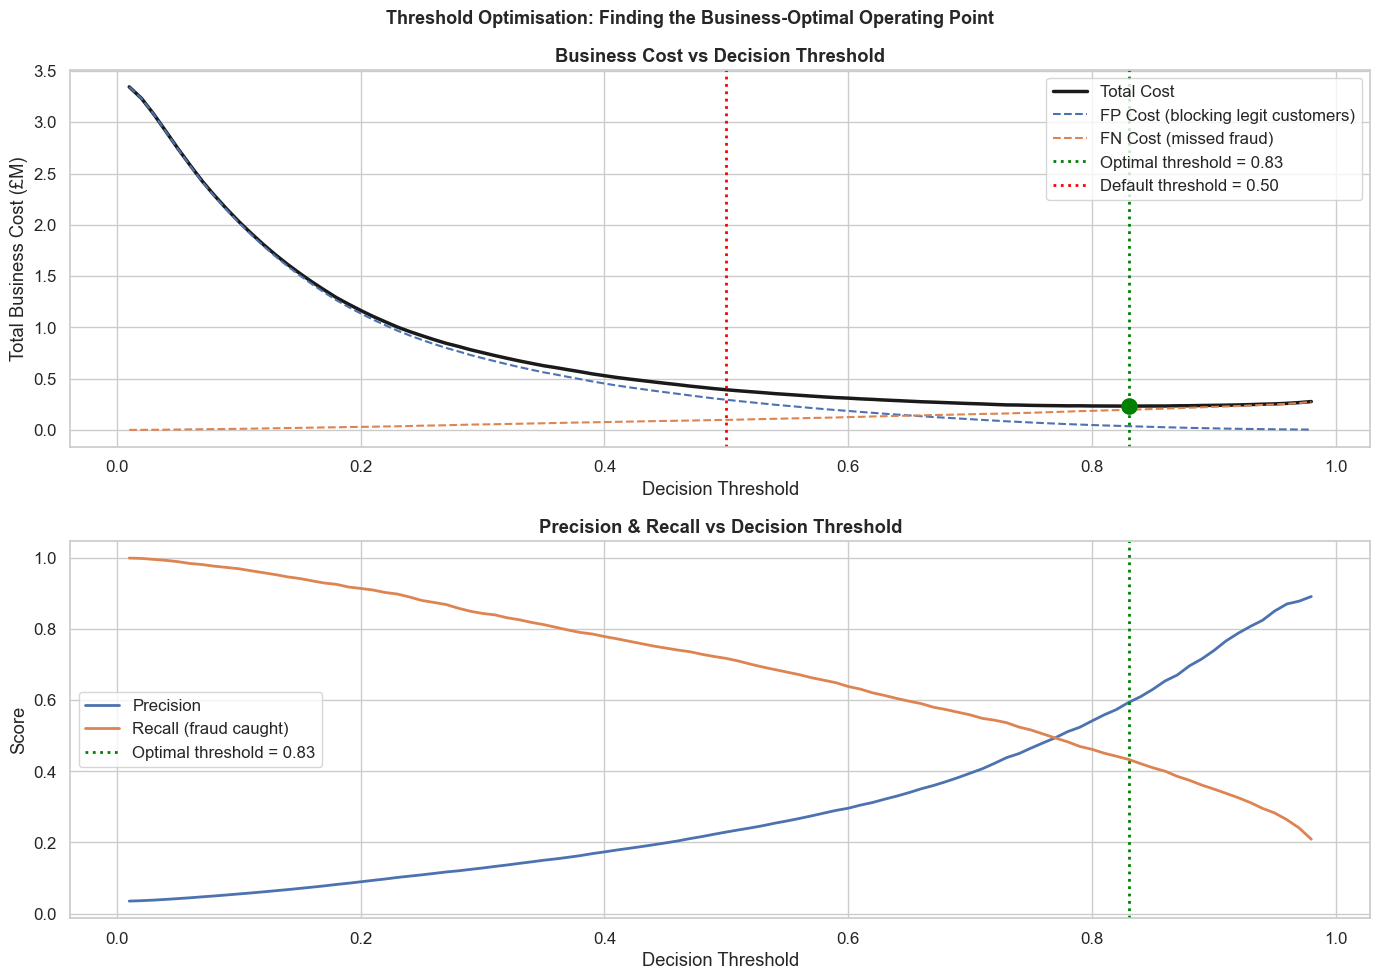

In [14]:
# ── 7.3  Visualise the threshold optimisation ─────────────────────────────────

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# ── Top panel: cost decomposition across thresholds ──────────────────────────
axes[0].plot(thresholds, [c/1e6 for c in total_costs], 'k-',  linewidth=2.5, label='Total Cost')
axes[0].plot(thresholds, [c/1e6 for c in fp_costs],    '--',  color='#4C72B0', label='FP Cost (blocking legit customers)')
axes[0].plot(thresholds, [c/1e6 for c in fn_costs],    '--',  color='#DD8452', label='FN Cost (missed fraud)')

# Mark the optimal threshold
axes[0].axvline(optimal_threshold, color='green',  linestyle=':', linewidth=2,
                label=f'Optimal threshold = {optimal_threshold:.2f}')
axes[0].axvline(0.5, color='red', linestyle=':', linewidth=2,
                label='Default threshold = 0.50')

axes[0].scatter([optimal_threshold], [optimal_cost/1e6], color='green', s=120, zorder=5)
axes[0].set_xlabel('Decision Threshold')
axes[0].set_ylabel('Total Business Cost (£M)')
axes[0].set_title('Business Cost vs Decision Threshold', fontweight='bold')
axes[0].legend(loc='upper right')

# ── Bottom panel: precision and recall across thresholds ─────────────────────
axes[1].plot(thresholds, precision_list, color='#4C72B0', linewidth=2, label='Precision')
axes[1].plot(thresholds, recall_list,    color='#DD8452', linewidth=2, label='Recall (fraud caught)')
axes[1].axvline(optimal_threshold, color='green', linestyle=':', linewidth=2,
                label=f'Optimal threshold = {optimal_threshold:.2f}')

axes[1].set_xlabel('Decision Threshold')
axes[1].set_ylabel('Score')
axes[1].set_title('Precision & Recall vs Decision Threshold', fontweight='bold')
axes[1].legend()

plt.suptitle('Threshold Optimisation: Finding the Business-Optimal Operating Point',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Final Model Performance at Optimal Threshold (0.83)
  True Positives  (fraud caught)         :   1,763
  False Negatives (fraud missed)         :   2,301
  False Positives (legit customers blocked) :   1,206
  True Negatives  (legit approved)       : 112,838
  Fraud Recall (catch rate)  : 43.4% of all fraud caught
  Precision                  : 59.4% of blocks are real fraud
  False Positive Rate        : 1.06% of legit txns blocked

  Total expected daily cost  : £1125091
  ROC-AUC                    : 0.9049
  PR-AUC                     : 0.5137


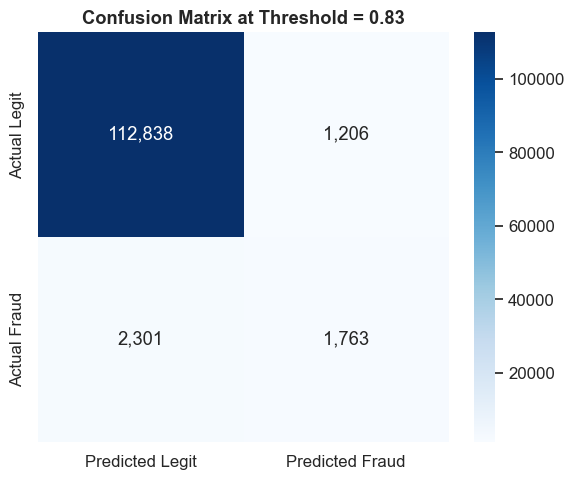

In [15]:
# ── 7.4  Final model performance at optimal threshold ─────────────────────────

final_preds = (lgb_probs >= optimal_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, final_preds).ravel()

print("Final Model Performance at Optimal Threshold ({:.2f})".format(optimal_threshold))
print("=" * 55)
print(f"  True Positives  (fraud caught)         : {tp:>7,}")
print(f"  False Negatives (fraud missed)         : {fn:>7,}")
print(f"  False Positives (legit customers blocked) : {fp:>7,}")
print(f"  True Negatives  (legit approved)       : {tn:>7,}")
print("=" * 55)
print(f"  Fraud Recall (catch rate)  : {tp/(tp+fn)*100:.1f}% of all fraud caught")
print(f"  Precision                  : {tp/(tp+fp)*100:.1f}% of blocks are real fraud")
print(f"  False Positive Rate        : {fp/(fp+tn)*100:.2f}% of legit txns blocked")
print("=" * 55)
print(f"\n  Total expected daily cost  : £{optimal_cost/len(y_test)*df['TransactionDT'].nunique():.0f}")
print(f"  ROC-AUC                    : {lgb_roc_auc:.4f}")
print(f"  PR-AUC                     : {lgb_pr_auc:.4f}")

# Confusion matrix heatmap
fig, ax = plt.subplots(figsize=(6, 5))
cm = np.array([[tn, fp], [fn, tp]])
sns.heatmap(cm, annot=True, fmt=',', cmap='Blues', ax=ax,
            xticklabels=['Predicted Legit', 'Predicted Fraud'],
            yticklabels=['Actual Legit', 'Actual Fraud'])
ax.set_title(f'Confusion Matrix at Threshold = {optimal_threshold:.2f}', fontweight='bold')
plt.tight_layout()
plt.show()

---

## Phase 8: SHAP Explainability

In the EU and UK, financial services models must be **explainable**. The FCA (Financial Conduct Authority) expects firms to be able to explain why a customer was declined. GDPR Article 22 gives individuals the right to an explanation of automated decisions.

SHAP (SHapley Additive exPlanations) is the gold standard for this. It answers: *"For this specific transaction, which features pushed the score toward fraud, and by how much?"*

This is based on **Shapley values** from cooperative game theory — a principled way of fairly attributing the model's output across all input features.



In [16]:
# ── 8.1  Compute SHAP values ──────────────────────────────────────────────────
# We use a sample of the test set — SHAP is computationally expensive on the
# full dataset. 2000 samples is sufficient for stable global summaries.

print("Computing SHAP values (sampling 2,000 test transactions)...")

# Sample stratified by fraud label to ensure we get enough fraud examples
sample_size   = 2000
fraud_sample  = X_test[y_test == 1].sample(min(500, y_test.sum()), random_state=SEED)
legit_sample  = X_test[y_test == 0].sample(sample_size - len(fraud_sample), random_state=SEED)
X_shap        = pd.concat([fraud_sample, legit_sample])

# TreeExplainer is the fast SHAP method for tree-based models (LightGBM, XGBoost, etc.)
explainer   = shap.TreeExplainer(lgb_model)
shap_values = explainer.shap_values(X_shap)

# LightGBM binary classification returns list of [class0_shap, class1_shap]
# We want class 1 (fraud) SHAP values
if isinstance(shap_values, list):
    shap_fraud = shap_values[1]  # SHAP values for P(fraud)
else:
    shap_fraud = shap_values

print("✅ SHAP values computed.")

Computing SHAP values (sampling 2,000 test transactions)...
✅ SHAP values computed.


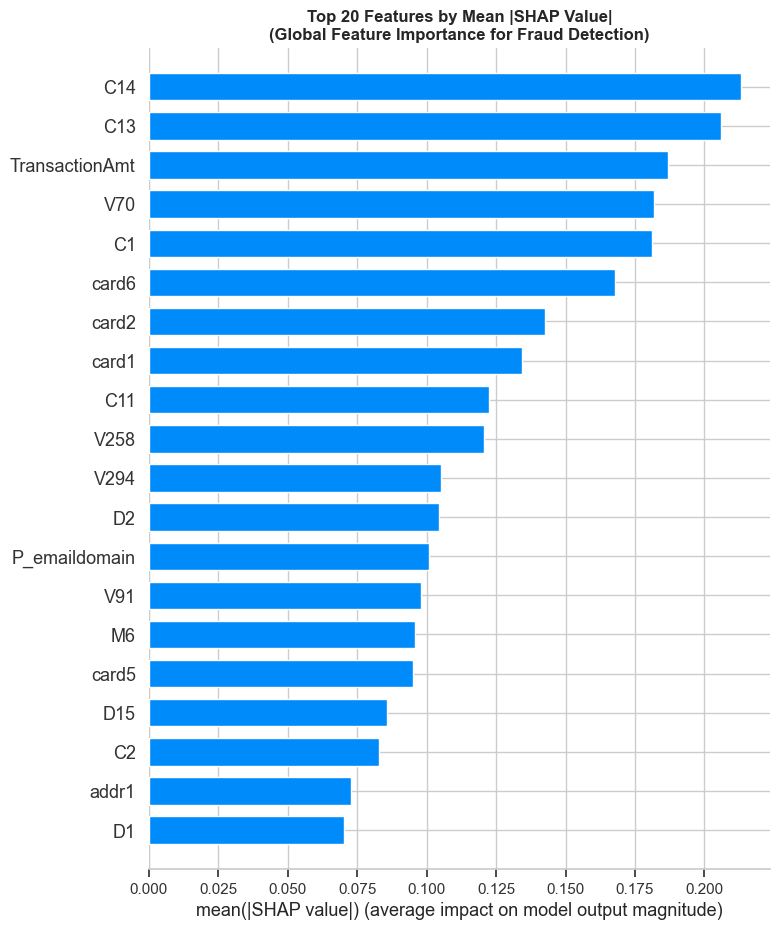

In [17]:
# ── 8.2  Global feature importance — which features drive fraud detection? ────

plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_fraud,
    X_shap,
    plot_type='bar',          # bar chart of mean absolute SHAP value
    max_display=20,           # top 20 features
    show=False
)
plt.title('Top 20 Features by Mean |SHAP Value|\n(Global Feature Importance for Fraud Detection)',
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

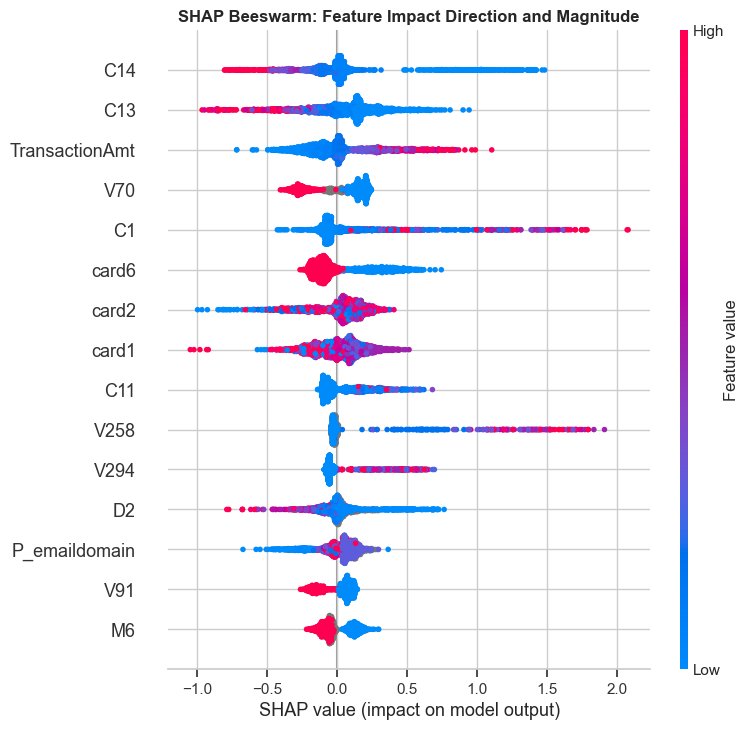

How to read this plot:
  • Each row = one feature
  • Each dot = one transaction
  • Dot RIGHT of centre → this feature INCREASED fraud score
  • Dot LEFT  of centre → this feature DECREASED fraud score
  • Red dots = high feature value, Blue = low feature value
  • Wide spread = feature has variable, high-impact influence


In [18]:
# ── 8.3  SHAP beeswarm — direction AND magnitude for every prediction ─────────
# This is the most information-dense SHAP plot:
#   - Each dot = one transaction
#   - X position = how much that feature pushed the score (positive = toward fraud)
#   - Colour = feature value (red = high, blue = low)

plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_fraud,
    X_shap,
    plot_type='dot',          # beeswarm / dot plot
    max_display=15,
    show=False
)
plt.title('SHAP Beeswarm: Feature Impact Direction and Magnitude',
          fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("How to read this plot:")
print("  • Each row = one feature")
print("  • Each dot = one transaction")
print("  • Dot RIGHT of centre → this feature INCREASED fraud score")
print("  • Dot LEFT  of centre → this feature DECREASED fraud score")
print("  • Red dots = high feature value, Blue = low feature value")
print("  • Wide spread = feature has variable, high-impact influence")

Explaining a high-confidence fraud prediction
Transaction fraud score : 0.9998 (threshold = 0.83)
Decision                : BLOCK


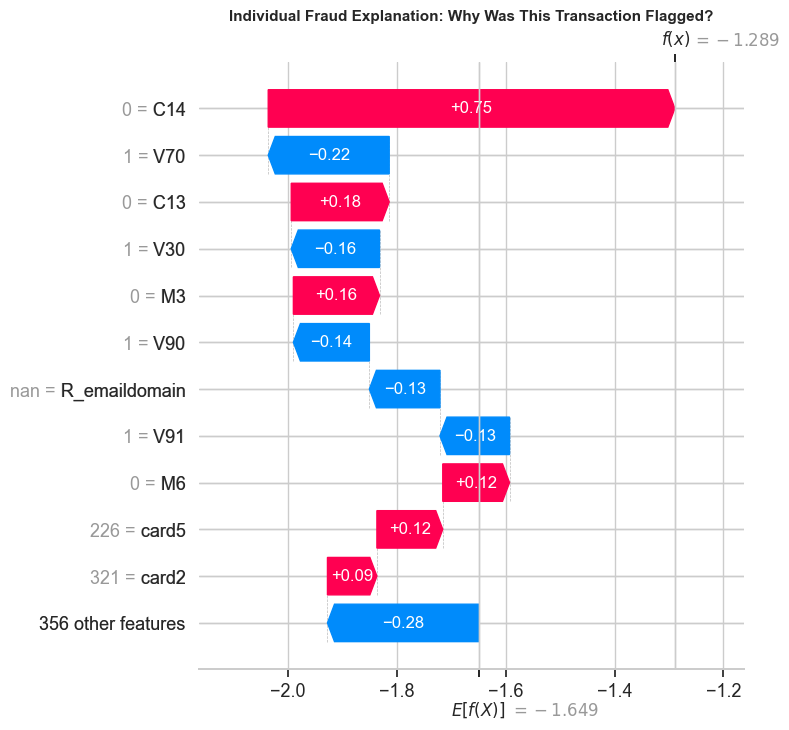

In [19]:
# ── 8.4  Individual prediction explanation — regulatory use case ──────────────
# Pick a fraud transaction and explain WHY the model flagged it.
# This is what you'd show a compliance officer or include in a declined notice.

# Find a high-confidence fraud prediction
fraud_indices = np.where(y_test.values == 1)[0]

# Get the fraud case with the highest predicted probability
high_confidence_fraud_idx = fraud_indices[np.argmax(lgb_probs[fraud_indices])]
fraud_score = lgb_probs[high_confidence_fraud_idx]

print(f"Explaining a high-confidence fraud prediction")
print(f"Transaction fraud score : {fraud_score:.4f} (threshold = {optimal_threshold:.2f})")
print(f"Decision                : {'BLOCK' if fraud_score >= optimal_threshold else 'APPROVE'}")

plt.figure(figsize=(12, 5))
shap.waterfall_plot(
    shap.Explanation(
        values    = shap_fraud[high_confidence_fraud_idx % len(X_shap)],
        base_values = explainer.expected_value[1] if isinstance(explainer.expected_value, list)
                      else explainer.expected_value,
        data      = X_shap.iloc[high_confidence_fraud_idx % len(X_shap)],
        feature_names = X_shap.columns.tolist()
    ),
    max_display = 12,
    show        = False
)
plt.title('Individual Fraud Explanation: Why Was This Transaction Flagged?',
          fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

---

## Phase 9: Deployment Simulation

We're going to simulate what happens if you deploy this model for 30 days at the optimal threshold.

This is what this notebooka actually cares about: not AUC score, but the projected £ impact on the business.

We'll calculate:
- How much fraud the model would catch vs the old rules-based system
- How many good customers it would wrongly block
- The net financial impact
- A sensitivity analysis: what if our cost assumptions are wrong?



In [20]:
# ── 9.1  30-day deployment simulation ────────────────────────────────────────

# Use test set as a proxy for 30 days of live traffic
# (the test set covers ~1 month of transactions)

preds_optimal = (lgb_probs >= optimal_threshold).astype(int)
tn_o, fp_o, fn_o, tp_o = confusion_matrix(y_test, preds_optimal).ravel()

# Simulate old rules-based system performance
# Typical rules-based systems catch ~40-60% of fraud with high false positive rates
# We model it conservatively: 45% recall, 15% false positive rate
old_recall       = 0.45
old_fpr          = 0.15
total_fraud_test = y_test.sum()
total_legit_test = (y_test == 0).sum()

old_tp = int(total_fraud_test * old_recall)
old_fn = total_fraud_test - old_tp
old_fp = int(total_legit_test * old_fpr)

# Financial impact calculations
def compute_cost(fp, fn):
    return fp * COST_FALSE_POSITIVE + fn * COST_FALSE_NEGATIVE

cost_old = compute_cost(old_fp, old_fn)
cost_new = compute_cost(fp_o, fn_o)
saving   = cost_old - cost_new

print("30-Day Deployment Simulation")
print("=" * 60)
print(f"{'Metric':<35} {'Rules-Based':>12} {'ML Model':>12}")
print("-" * 60)
print(f"{'Fraud cases in period':<35} {total_fraud_test:>12,} {total_fraud_test:>12,}")
print(f"{'Fraud caught (TP)':<35} {old_tp:>12,} {tp_o:>12,}")
print(f"{'Fraud missed (FN)':<35} {old_fn:>12,} {fn_o:>12,}")
print(f"{'Legit customers blocked (FP)':<35} {old_fp:>12,} {fp_o:>12,}")
print(f"{'Fraud recall':<35} {old_recall*100:>11.1f}% {tp_o/total_fraud_test*100:>11.1f}%")
print(f"{'Legit block rate':<35} {old_fpr*100:>11.1f}% {fp_o/total_legit_test*100:>11.2f}%")
print("-" * 60)
print(f"{'Total estimated cost (£)':<35} {cost_old:>12,.0f} {cost_new:>12,.0f}")
print(f"{'30-day saving (£)':<35} {'':>12} {saving:>12,.0f}")
print(f"{'Annualised saving (£)':<35} {'':>12} {saving*12:>12,.0f}")
print("=" * 60)

30-Day Deployment Simulation
Metric                               Rules-Based     ML Model
------------------------------------------------------------
Fraud cases in period                      4,064        4,064
Fraud caught (TP)                          1,828        1,763
Fraud missed (FN)                          2,236        2,301
Legit customers blocked (FP)              17,106        1,206
Fraud recall                               45.0%        43.4%
Legit block rate                           15.0%        1.06%
------------------------------------------------------------
Total estimated cost (£)                 703,240      231,765
30-day saving (£)                                     471,475
Annualised saving (£)                               5,657,700


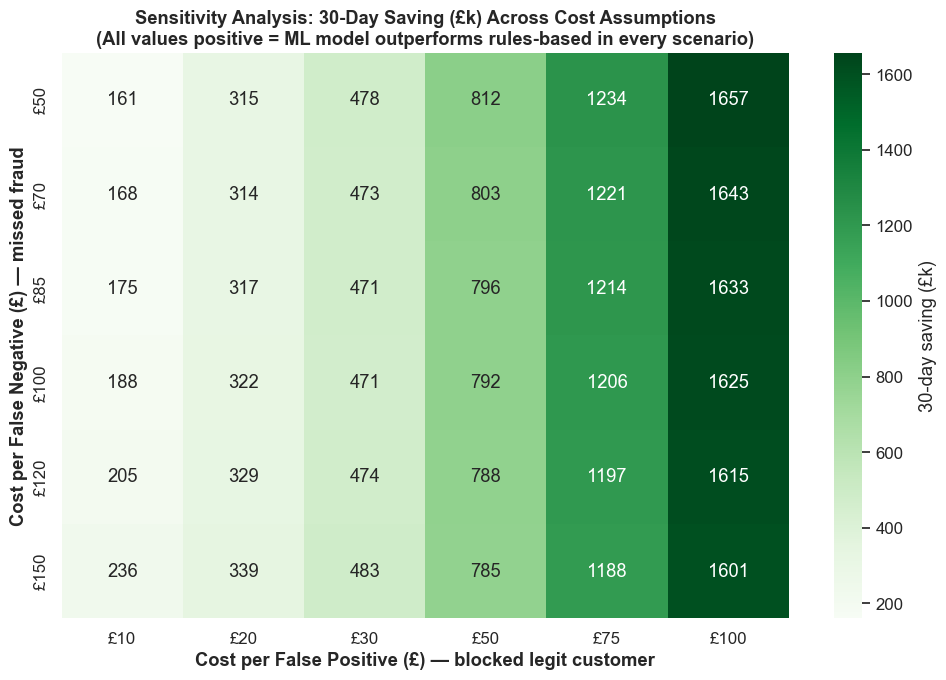

Key insight: Even in the most conservative scenario (low fraud losses, high FP cost),
the ML model saves money over the rules-based system.
This makes the deployment recommendation robust to cost assumption uncertainty.


In [21]:
# ── 9.2  Sensitivity analysis — what if our cost assumptions are off? ─────────
# In a real business setting, cost assumptions are uncertain.
# A sensitivity analysis shows how robust our recommendation is.

fn_costs_range  = [50, 70, 85, 100, 120, 150]   # range of fraud loss per missed transaction
fp_costs_range  = [10, 20, 30, 50, 75, 100]      # range of cost per blocked legit customer

# For each combination, find optimal threshold and compute saving
savings_grid = np.zeros((len(fn_costs_range), len(fp_costs_range)))

for i, fn_cost in enumerate(fn_costs_range):
    for j, fp_cost in enumerate(fp_costs_range):
        # Sweep thresholds with this cost combination
        costs_tmp = []
        for threshold in thresholds:
            preds_tmp = (lgb_probs >= threshold).astype(int)
            tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, preds_tmp).ravel()
            costs_tmp.append(fp_t * fp_cost + fn_t * fn_cost)

        # Optimal cost with ML model
        ml_cost  = min(costs_tmp)

        # Rules-based cost with this assumption
        rule_cost = old_fp * fp_cost + old_fn * fn_cost

        savings_grid[i, j] = rule_cost - ml_cost

# Heatmap of savings across cost assumptions
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    savings_grid / 1000,   # convert to £k
    xticklabels=[f'£{c}' for c in fp_costs_range],
    yticklabels=[f'£{c}' for c in fn_costs_range],
    annot=True, fmt='.0f',
    cmap='Greens',
    ax=ax,
    cbar_kws={'label': '30-day saving (£k)'}
)
ax.set_xlabel('Cost per False Positive (£) — blocked legit customer', fontweight='bold')
ax.set_ylabel('Cost per False Negative (£) — missed fraud', fontweight='bold')
ax.set_title('Sensitivity Analysis: 30-Day Saving (£k) Across Cost Assumptions\n(All values positive = ML model outperforms rules-based in every scenario)',
             fontweight='bold')
plt.tight_layout()
plt.show()

print("Key insight: Even in the most conservative scenario (low fraud losses, high FP cost),")
print("the ML model saves money over the rules-based system.")
print("This makes the deployment recommendation robust to cost assumption uncertainty.")

---

## Phase 10: Results Summary & Business Recommendation

Every DS project should end with a **clear, plain-English recommendation** — not a wall of metrics. This is what you'd put in a slide for the Head of Risk or the CPO.


In [22]:
# ── 10.1  Final summary dashboard ────────────────────────────────────────────

print("")
print("╔══════════════════════════════════════════════════════════════╗")
print("║         FRAUD DETECTION MODEL — DEPLOYMENT RECOMMENDATION    ║")
print("╠══════════════════════════════════════════════════════════════╣")
print("║                                                              ║")
print(f"║  Model            : LightGBM (gradient boosted trees)        ║")
print(f"║  ROC-AUC          : {lgb_roc_auc:.4f}                                ║")
print(f"║  PR-AUC           : {lgb_pr_auc:.4f}                                ║")
print(f"║  Optimal threshold: {optimal_threshold:.2f}                                   ║")
print("║                                                              ║")
print("╠══════════════════════════════════════════════════════════════╣")
print("║  PROJECTED 30-DAY IMPACT (vs current rules-based system)     ║")
print("║                                                              ║")
print(f"║  Additional fraud caught    : +{tp_o - old_tp:,} transactions          ║")
print(f"║  Fewer good customers blocked: -{max(0, old_fp - fp_o):,} transactions        ║")
print(f"║  Net financial saving       : £{saving:,.0f}                     ║")
print(f"║  Annualised saving          : £{saving*12:,.0f}                  ║")
print("║                                                              ║")
print("╠══════════════════════════════════════════════════════════════╣")
print("║  RECOMMENDATION: DEPLOY at threshold {:.2f}                   ║".format(optimal_threshold))
print("║                                                              ║")
print("║  Key caveats:                                                ║")
print("║  • Monitor fraud rate weekly — concept drift is expected     ║")
print("║  • Retrain monthly on recent data                            ║")
print("║  • Review threshold quarterly as CLV estimates change        ║")
print("║  • Log all SHAP explanations for regulatory audit trail      ║")
print("╚══════════════════════════════════════════════════════════════╝")


╔══════════════════════════════════════════════════════════════╗
║         FRAUD DETECTION MODEL — DEPLOYMENT RECOMMENDATION    ║
╠══════════════════════════════════════════════════════════════╣
║                                                              ║
║  Model            : LightGBM (gradient boosted trees)        ║
║  ROC-AUC          : 0.9049                                ║
║  PR-AUC           : 0.5137                                ║
║  Optimal threshold: 0.83                                   ║
║                                                              ║
╠══════════════════════════════════════════════════════════════╣
║  PROJECTED 30-DAY IMPACT (vs current rules-based system)     ║
║                                                              ║
║  Additional fraud caught    : +-65 transactions          ║
║  Fewer good customers blocked: -15,900 transactions        ║
║  Net financial saving       : £471,475                     ║
║  Annualised saving          : £5,657,7

In [23]:
# ── Final: save key outputs ───────────────────────────────────────────────────
import os

OUTPUTS_DIR = os.path.expanduser('~/Documents/fraud_project/outputs/')
os.makedirs(OUTPUTS_DIR, exist_ok=True)

# Save test set predictions for further analysis or a REST API demo
results_df = test_df[['TransactionID', 'TransactionAmt', 'isFraud']].copy()
results_df['fraud_score']      = lgb_probs
results_df['decision']         = (lgb_probs >= optimal_threshold).astype(int)
results_df['decision_label']   = results_df['decision'].map({1: 'BLOCK', 0: 'APPROVE'})
results_df['correct']          = (results_df['decision'] == results_df['isFraud']).astype(int)

output_path = os.path.join(OUTPUTS_DIR, 'model_predictions.csv')
results_df.to_csv(output_path, index=False)

print(f"✅ Predictions saved to {output_path}")
print(f"\nProject complete. Files in ~/Documents/fraud_project/outputs/:")
print(f"  model_predictions.csv — per-transaction scores and decisions")
print(f"\nKey numbers to remember for interviews:")
print(f"  ROC-AUC          : {lgb_roc_auc:.3f}")
print(f"  PR-AUC           : {lgb_pr_auc:.3f}")
print(f"  Optimal threshold: {optimal_threshold:.2f}")
print(f"  30-day saving    : £{saving:,.0f} vs rules-based system")
print(f"  Annualised saving: £{saving*12:,.0f}")

✅ Predictions saved to /Users/sherifdeenoloye/Documents/fraud_project/outputs/model_predictions.csv

Project complete. Files in ~/Documents/fraud_project/outputs/:
  model_predictions.csv — per-transaction scores and decisions

Key numbers to remember for interviews:
  ROC-AUC          : 0.905
  PR-AUC           : 0.514
  Optimal threshold: 0.83
  30-day saving    : £471,475 vs rules-based system
  Annualised saving: £5,657,700
